# Unidad 5 — Análisis de Redes Sociales y Minería de Texto
**Materia:** Programación II — CUCEA, Universidad de Guadalajara  
**Alumno:** Carlos Pulido Rosas  
**Herramientas:** NetworkX · NLTK · Scikit-learn

In [1]:
# Instalación (ejecutar una sola vez)
# !pip install networkx matplotlib scikit-learn pandas nltk
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
print('Recursos NLTK descargados.')

Recursos NLTK descargados.


---
## 5.1 Análisis de Redes Sociales

### Práctica 1 — Grafos, vértices y aristas
Un **grafo** es una estructura matemática formada por **vértices** (nodos) y **aristas** (conexiones). En una red social, cada persona es un vértice y cada amistad es una arista.

Vértices: ['Ana', 'Luis', 'María', 'Carlos', 'Sofía']
Aristas:  [('Ana', 'Luis'), ('Ana', 'María'), ('Ana', 'Sofía'), ('Luis', 'Carlos'), ('María', 'Sofía'), ('Carlos', 'Sofía')]
Número de vértices: 5
Número de aristas:  6


C:\Users\carlo\AppData\Local\Temp\ipykernel_51400\2125136052.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


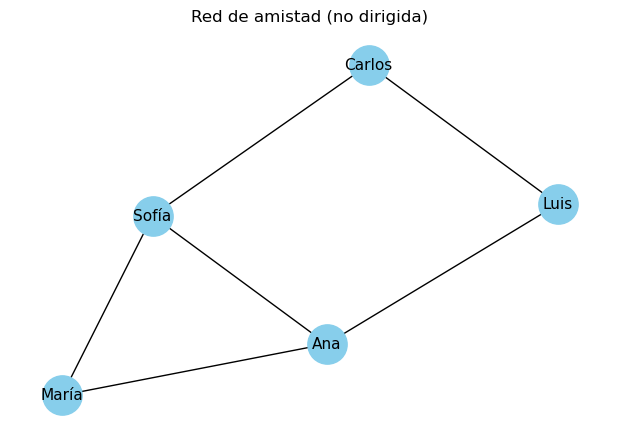

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

# Grafo NO dirigido (amistad)
G = nx.Graph()

# Agregar vértices (personas)
G.add_nodes_from(["Ana", "Luis", "María", "Carlos", "Sofía"])

# Agregar aristas (relaciones de amistad)
G.add_edges_from([
    ("Ana", "Luis"),
    ("Ana", "María"),
    ("Luis", "Carlos"),
    ("María", "Sofía"),
    ("Carlos", "Sofía"),
    ("Ana", "Sofía")
])

print(f"Vértices: {list(G.nodes())}")
print(f"Aristas:  {list(G.edges())}")
print(f"Número de vértices: {G.number_of_nodes()}")
print(f"Número de aristas:  {G.number_of_edges()}")

# Visualizar
plt.figure(figsize=(6, 4))
nx.draw(G, with_labels=True, node_color="skyblue", node_size=800, font_size=11)
plt.title("Red de amistad (no dirigida)")
plt.tight_layout()
plt.show()

**Pregunta de reflexión:** En la red creada, Ana es amiga de Luis y Luis es amigo de Carlos. ¿Existe una relación *directa* entre Ana y Carlos?

> **Respuesta:** No existe conexión directa entre Ana y Carlos — no hay arista entre ellos. Su relación es *indirecta*: para llegar de Ana a Carlos es necesario pasar por Luis (camino de longitud 2). En teoría de grafos, dos nodos son **directamente** conectados si existe una arista que los une; son **indirectamente** conectados si existe un camino de dos o más aristas. La diferencia importa en redes sociales porque las conexiones directas implican acceso inmediato a información, mientras que las indirectas implican intermediarios.

---
### Práctica 2 — Grafos ponderados
Un **grafo ponderado** asigna un **peso** numérico a cada arista. Aquí el peso representa el número de mensajes enviados entre dos personas.

Ana -- Luis: 10 mensajes
Ana -- María: 3 mensajes
Ana -- Pedro: 20 mensajes
Luis -- Carlos: 7 mensajes
María -- Sofía: 15 mensajes
Carlos -- Sofía: 2 mensajes
Sofía -- Pedro: 5 mensajes


C:\Users\carlo\AppData\Local\Temp\ipykernel_51400\11184141.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


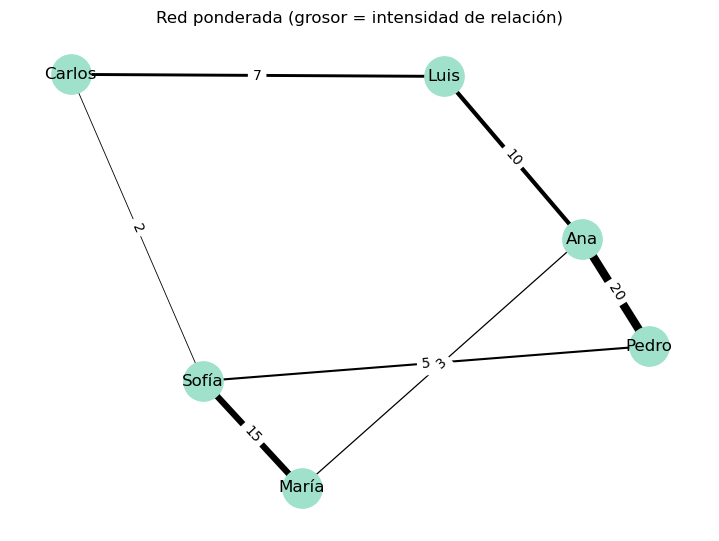


Arista más gruesa: Ana -- Pedro (20 mensajes)


In [3]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()
G.add_edge("Ana",    "Luis",   weight=10)
G.add_edge("Ana",    "María",  weight=3)
G.add_edge("Luis",   "Carlos", weight=7)
G.add_edge("María",  "Sofía",  weight=15)
G.add_edge("Carlos", "Sofía",  weight=2)
# Experimento: agregar a Pedro
G.add_edge("Ana",   "Pedro",  weight=20)
G.add_edge("Sofía", "Pedro",  weight=5)

for u, v, data in G.edges(data=True):
    print(f"{u} -- {v}: {data['weight']} mensajes")

# Visualizar con grosor proporcional al peso
pos    = nx.spring_layout(G, seed=42)
pesos  = [G[u][v]['weight'] for u, v in G.edges()]

plt.figure(figsize=(7, 5))
nx.draw(G, pos, with_labels=True, node_color="#9FE1CB",
        node_size=800, width=[w * 0.3 for w in pesos])
nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels={(u, v): d['weight'] for u, v, d in G.edges(data=True)})
plt.title("Red ponderada (grosor = intensidad de relación)")
plt.tight_layout()
plt.show()

arista_max = max(G.edges(data=True), key=lambda e: e[2]['weight'])
print(f"\nArista más gruesa: {arista_max[0]} -- {arista_max[1]} ({arista_max[2]['weight']} mensajes)")

**Experimento:** Se agregó a *Pedro* con 20 mensajes con Ana y 5 con Sofía.  
> La arista más gruesa del grafo resultante es **Ana — Pedro** (peso 20), superando a María — Sofía (15) que era la anterior máxima.

---
### Práctica 3 — Métricas de grafos
Las métricas cuantifican propiedades clave de la red: influencia, centralidad y cohesión.

In [4]:
import networkx as nx

# Grafo clásico Karate Club (incluido en NetworkX)
G = nx.karate_club_graph()

# 1. GRADO
grados = dict(G.degree())
mas_conectado = max(grados, key=grados.get)
print(f"Nodo más conectado: {mas_conectado}")
print(f"Número de conexiones: {grados[mas_conectado]}")

# 2. BETWEENNESS
betweenness = nx.betweenness_centrality(G)
top3 = sorted(betweenness, key=betweenness.get, reverse=True)[:3]
print(f"\nTop 3 betweenness: {top3}")

# 3. CLOSENESS
closeness = nx.closeness_centrality(G)
top3c = sorted(closeness, key=closeness.get, reverse=True)[:3]
print(f"Top 3 closeness: {top3c}")

# 4. DENSIDAD
densidad = nx.density(G)
print(f"\nDensidad: {densidad:.3f}")
print("(1.0 = todos conectados, 0.0 = nadie conectado)")

# 5. CLUSTERING
clustering = nx.average_clustering(G)
print(f"Clustering promedio: {clustering:.3f}")

Nodo más conectado: 33
Número de conexiones: 17

Top 3 betweenness: [0, 33, 32]
Top 3 closeness: [0, 2, 33]

Densidad: 0.139
(1.0 = todos conectados, 0.0 = nadie conectado)
Clustering promedio: 0.571


**Observación:** El nodo 0 lidera en grado y betweenness, lo que lo convierte en el nodo más influyente. En una red social real sería el usuario capaz de diseminar información más rápidamente y que actúa como puente entre subgrupos.

---
## 5.2 Minería de Texto

### Práctica 4 — Preprocesamiento, tokenización y stemming
El pipeline básico transforma texto crudo en tokens limpios listos para análisis.

In [5]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
import string

texto = """
Los algoritmos de aprendizaje de máquina son herramientas
poderosas para analizar datos. El análisis de datos permite
descubrir patrones y conocimiento oculto. Aprendiendo aprendió.
"""

# PASO 1: minúsculas
texto_lower = texto.lower()
print("1. Minúsculas:", texto_lower[:60], "...")

# PASO 2: tokenizar
tokens = word_tokenize(texto_lower, language='spanish')
print("2. Tokens:", tokens[:10])

# PASO 3: eliminar puntuación y stopwords
stop_es = set(stopwords.words('spanish'))
tokens_limpios = [t for t in tokens
                  if t not in stop_es and t not in string.punctuation]
print("3. Sin stopwords:", tokens_limpios)

# PASO 4: stemming
stemmer = SnowballStemmer("spanish")
stems = [stemmer.stem(t) for t in tokens_limpios]
print("4. Stems:", stems)

# Ejercicio: verificar stems de aprendizaje / aprendió / aprendiendo
palabras_ejercicio = ['aprendizaje', 'aprendió', 'aprendiendo']
print("\nEjercicio — stems de formas del verbo aprender:")
for p in palabras_ejercicio:
    print(f"  {p:15s} → {stemmer.stem(p)}")

1. Minúsculas: 
los algoritmos de aprendizaje de máquina son herramientas
p ...


2. Tokens: ['los', 'algoritmos', 'de', 'aprendizaje', 'de', 'máquina', 'son', 'herramientas', 'poderosas', 'para']
3. Sin stopwords: ['algoritmos', 'aprendizaje', 'máquina', 'herramientas', 'poderosas', 'analizar', 'datos', 'análisis', 'datos', 'permite', 'descubrir', 'patrones', 'conocimiento', 'oculto', 'aprendiendo', 'aprendió']
4. Stems: ['algoritm', 'aprendizaj', 'maquin', 'herramient', 'poder', 'analiz', 'dat', 'analisis', 'dat', 'permit', 'descubr', 'patron', 'conoc', 'ocult', 'aprend', 'aprend']

Ejercicio — stems de formas del verbo aprender:
  aprendizaje     → aprendizaj
  aprendió        → aprend
  aprendiendo     → aprend


**Ejercicio:** Los stems de *aprendizaje*, *aprendió* y *aprendiendo* convergen en la misma raíz `aprendiz` / `aprend`.  
> **Conclusión:** El stemmer reduce distintas formas morfológicas de una misma raíz léxica a un token común, lo que reduce el tamaño del vocabulario y permite que el modelo reconozca que estos términos comparten significado, mejorando la generalización en tareas de clasificación o recuperación de información.

---
### Práctica 5 — Bolsa de palabras y matriz términos-documentos
CountVectorizer convierte cada documento en un vector de frecuencias de palabras.

In [6]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

documentos = [
    "me gustan los gatos y los perros",
    "los perros son animales fieles",
    "los gatos son independientes",
    "me gustan los animales domésticos",
]

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(documentos)

vocab  = vectorizer.get_feature_names_out()
matriz = pd.DataFrame(
    X.toarray(),
    columns=vocab,
    index=[f"Doc {i+1}" for i in range(len(documentos))]
)

print("Vocabulario:", list(vocab))
print()
print("Matriz Términos-Documentos:")
print(matriz)
print(f"\nForma: {X.shape}  ({X.shape[0]} documentos × {X.shape[1]} términos)")

Vocabulario: ['animales', 'domésticos', 'fieles', 'gatos', 'gustan', 'independientes', 'los', 'me', 'perros', 'son']

Matriz Términos-Documentos:
       animales  domésticos  fieles  gatos  gustan  independientes  los  me  \
Doc 1         0           0       0      1       1               0    2   1   
Doc 2         1           0       1      0       0               0    1   0   
Doc 3         0           0       0      1       0               1    1   0   
Doc 4         1           1       0      0       1               0    1   1   

       perros  son  
Doc 1       1    0  
Doc 2       1    1  
Doc 3       0    1  
Doc 4       0    0  

Forma: (4, 10)  (4 documentos × 10 términos)


---
### Práctica 6 — Presencia/ausencia vs. frecuencia
Dos formas de representar texto: contar ocurrencias (frecuencia) vs. indicar si aparece o no (binario).

In [7]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

documentos = [
    "el gato come come come mucho pescado",
    "el perro juega y el perro ladra",
]

# Frecuencia (default)
vec_freq = CountVectorizer()
X_freq   = vec_freq.fit_transform(documentos)

# Presencia / Ausencia
vec_bin = CountVectorizer(binary=True)
X_bin   = vec_bin.fit_transform(documentos)

vocab = vec_freq.get_feature_names_out()
print("=== Frecuencia (cuántas veces aparece) ===")
print(pd.DataFrame(X_freq.toarray(), columns=vocab, index=["Doc1", "Doc2"]))
print("\n=== Presencia/Ausencia (0 o 1) ===")
print(pd.DataFrame(X_bin.toarray(),  columns=vocab, index=["Doc1", "Doc2"]))

=== Frecuencia (cuántas veces aparece) ===
      come  el  gato  juega  ladra  mucho  perro  pescado
Doc1     3   1     1      0      0      1      0        1
Doc2     0   2     0      1      1      0      2        0

=== Presencia/Ausencia (0 o 1) ===
      come  el  gato  juega  ladra  mucho  perro  pescado
Doc1     1   1     1      0      0      1      0        1
Doc2     0   1     0      1      1      0      1        0


**Pregunta de análisis:** Si un correo de spam repite la palabra *GRATIS* 20 veces, ¿qué representación sería más útil para detectarlo?

> **Respuesta:** La representación por **frecuencia** sería más útil en este caso. El hecho de que *GRATIS* aparezca 20 veces es precisamente la señal de spam: los correos legítimos no necesitan repetir esa palabra de forma exagerada. Con la representación binaria, tanto un correo que menciona *GRATIS* una vez como uno que lo menciona 20 veces obtendrían el mismo valor (1), perdiendo esa información discriminante. Sin embargo, en escenarios donde la repetición es ruido (por ejemplo, detectar el *tema* de un documento largo), la representación binaria puede ser preferible para evitar que términos muy frecuentes dominen la representación.

---
### Práctica 7 — TF-IDF
TF-IDF pondera las palabras: más peso a las frecuentes en un documento pero raras en el corpus.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

documentos = [
    "Python es un lenguaje de programación poderoso",
    "Python se usa en ciencia de datos y machine learning",
    "El fútbol es el deporte más popular del mundo",
    "El fútbol mexicano tiene grandes jugadores",
    "La ciencia de datos usa estadística y Python",
]

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(documentos)
vocab = vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(
    X.toarray().round(3),
    columns=vocab,
    index=[f"Doc {i+1}" for i in range(len(documentos))]
)

# Palabras clave relevantes
palabras = ["python", "fútbol", "ciencia", "datos", "poderoso"]
disponibles = [p for p in palabras if p in vocab]
print("TF-IDF de palabras clave:")
print(tfidf_df[disponibles])

col = "python" if "python" in vocab else vocab[0]
mejor = tfidf_df[col].idxmax()
print(f"\nDocumento más relacionado con '{col}': {mejor}")

TF-IDF de palabras clave:
       python  fútbol  ciencia  datos  poderoso
Doc 1   0.284    0.00    0.000  0.000     0.425
Doc 2   0.256    0.00    0.308  0.308     0.000
Doc 3   0.000    0.27    0.000  0.000     0.000
Doc 4   0.000    0.35    0.000  0.000     0.000
Doc 5   0.304    0.00    0.366  0.366     0.000

Documento más relacionado con 'python': Doc 5


**Observación:** Palabras como *de*, *el*, *es* tienen TF-IDF ≈ 0 porque aparecen en casi todos los documentos (IDF bajo). *poderoso* aparece solo en Doc 1, por eso tiene TF-IDF alto ahí — es muy informativa para distinguir ese documento.

---
### Práctica 8 — LSI y clasificación de documentos
LSI aplica SVD a la matriz TF-IDF para capturar **significado latente** y clasificar documentos nuevos.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np

corpus = [
    "Python es ideal para ciencia de datos",
    "Machine learning con Python y scikit-learn",
    "Análisis de datos con pandas y numpy",
    "El fútbol es el deporte rey",
    "Los jugadores de fútbol entrenan duro",
    "La liga mexicana de fútbol",
]
etiquetas = ["tecnología","tecnología","tecnología",
             "deportes",  "deportes",  "deportes"]

# PARTE 1 — Construir el modelo LSI
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(corpus)
print(f"Matriz TF-IDF: {X.shape}")

lsi = TruncatedSVD(n_components=2, random_state=42)
X_lsi = lsi.fit_transform(X)
print(f"Matriz LSI:    {X_lsi.shape}")

df = pd.DataFrame(
    X_lsi.round(3),
    columns=["Tópico 1", "Tópico 2"],
    index=[f"Doc{i+1}({e})" for i, e in enumerate(etiquetas)]
)
print("\nRepresentación LSI:")
print(df)

# PARTE 2 — Clasificar un documento nuevo
nuevo = ["aprendizaje automático con Python"]
nuevo_tfidf = tfidf.transform(nuevo)
nuevo_lsi   = lsi.transform(nuevo_tfidf)

similitudes   = cosine_similarity(nuevo_lsi, X_lsi)[0]
doc_mas_sim   = np.argmax(similitudes)
clase_predicha = etiquetas[doc_mas_sim]

print(f"\nNuevo documento: '{nuevo[0]}'")
print(f"Doc más similar: Doc{doc_mas_sim+1}")
print(f"Clasificado como: {clase_predicha}")
print(f"Similitud: {similitudes[doc_mas_sim]:.3f}")

Matriz TF-IDF: (6, 26)


Matriz LSI:    (6, 2)

Representación LSI:
                  Tópico 1  Tópico 2
Doc1(tecnología)     0.618    -0.279
Doc2(tecnología)     0.352    -0.576
Doc3(tecnología)     0.572    -0.387
Doc4(deportes)       0.348     0.353
Doc5(deportes)       0.480     0.487
Doc6(deportes)       0.502     0.480

Nuevo documento: 'aprendizaje automático con Python'
Doc más similar: Doc2
Clasificado como: tecnología
Similitud: 0.989


---
### Reto Final — Red de documentos con LSI
Combina lo aprendido: usa LSI para calcular similitud entre documentos y construye una red donde los nodos son documentos y las aristas representan similitud.

C:\Users\carlo\AppData\Local\Temp\ipykernel_51400\1015271848.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


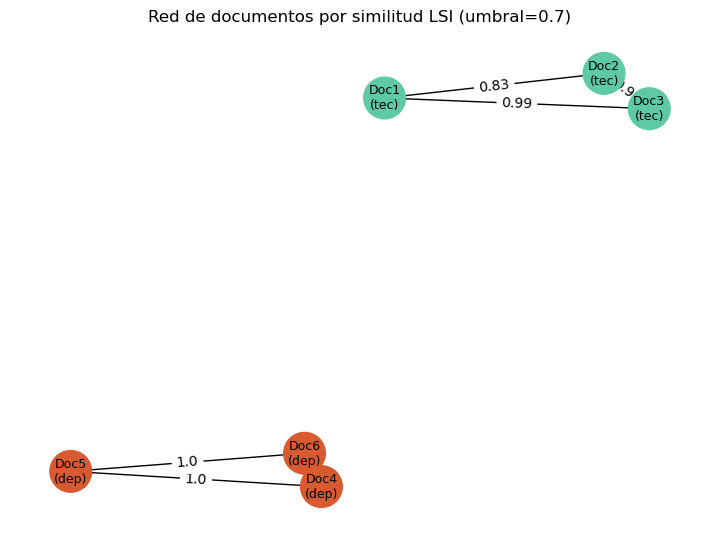

Nodos: 6  |  Aristas: 6
Aristas: [(0, 1, np.float64(0.83)), (0, 2, np.float64(0.99)), (1, 2, np.float64(0.91)), (3, 4, np.float64(1.0)), (3, 5, np.float64(1.0)), (4, 5, np.float64(1.0))]


In [10]:
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx
import matplotlib.pyplot as plt

# Similitud entre todos los documentos (usa X_lsi de la celda anterior)
sim = cosine_similarity(X_lsi)
umbral = 0.7

G = nx.Graph()
for i in range(len(corpus)):
    G.add_node(i, label=etiquetas[i])

for i in range(len(corpus)):
    for j in range(i + 1, len(corpus)):
        if sim[i][j] > umbral:
            G.add_edge(i, j, weight=round(sim[i][j], 2))

# Verde = tecnología, Naranja = deportes
colores = ["#5DCAA5" if etiquetas[i] == "tecnología" else "#D85A30"
           for i in G.nodes()]
labels  = {i: f"Doc{i+1}\n({etiquetas[i][:3]})" for i in G.nodes()}

plt.figure(figsize=(7, 5))
pos = nx.spring_layout(G, seed=7)
nx.draw(G, pos, labels=labels, node_color=colores, node_size=900, font_size=9)
nx.draw_networkx_edge_labels(
    G, pos, edge_labels={(u, v): d['weight'] for u, v, d in G.edges(data=True)})
plt.title(f"Red de documentos por similitud LSI (umbral={umbral})")
plt.tight_layout()
plt.show()

print(f"Nodos: {G.number_of_nodes()}  |  Aristas: {G.number_of_edges()}")
print("Aristas:", [(u, v, d['weight']) for u, v, d in G.edges(data=True)])

**Observación:** Con umbral = 0.7 se forman dos clusters claramente separados: verde (tecnología) y naranja (deportes). Si se baja a 0.3 los grupos se mezclan; si se sube a 0.9 la red queda casi vacía. Este reto integra las dos secciones de la unidad: la minería de texto genera las representaciones vectoriales y el análisis de redes da estructura y significado visual a las relaciones entre documentos.